# Mushroom Classification: Edible or Poisonous?

**The Idea:** This model predicts whether a mushroom is edible or poisonous
from features you can see or smell, such as its cap colour, odour and gill size.
Many poisonous mushrooms look like edible ones, so a quick, reliable check
could help foragers avoid dangerous mistakes.

In [1]:
import pandas as pd


## 1. Data Preparation

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

columns = ["class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
           "gill-attachment", "gill-spacing", "gill-size", "gill-color",
           "stalk-shape", "stalk-root", "stalk-surface-above-ring",
           "stalk-surface-below-ring", "stalk-color-above-ring",
           "stalk-color-below-ring", "veil-type", "veil-color", "ring-number",
           "ring-type", "spore-print-color", "population", "habitat"]

df = pd.read_csv(url, names=columns)

print(df.shape)
df.head()

(8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
df.shape

(8124, 23)

In [4]:
df.isnull().sum()

,0
class,0
cap-shape,0
cap-surface,0
cap-color,0
bruises,0
odor,0
gill-attachment,0
gill-spacing,0
gill-size,0
gill-color,0


In [5]:
(df == "?").sum()

,0
class,0
cap-shape,0
cap-surface,0
cap-color,0
bruises,0
odor,0
gill-attachment,0
gill-spacing,0
gill-size,0
gill-color,0


In [6]:
df = df.drop(columns=["stalk-root"])
df.shape

(8124, 22)

In [7]:
df["class"].value_counts()

,count
class,
e,4208
p,3916


In [8]:
X = df.drop(columns=["class"])
y = df["class"]

print(X.shape)
print(y.shape)

(8124, 21)
(8124,)


In [9]:
X = pd.get_dummies(X)
X.shape

(8124, 112)

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape)
print(X_test.shape)

(6499, 112)
(1625, 112)


## 2. Model Building

In [11]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

## 3. Evaluation

In [12]:
from sklearn.metrics import accuracy_score

tree_pred = tree.predict(X_test)
tree_acc = accuracy_score(y_test, tree_pred)

print("Decision Tree accuracy:", tree_acc)

Decision Tree accuracy: 1.0


In [13]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)
knn_acc = accuracy_score(y_test, knn_pred)

print("KNN accuracy:", knn_acc)

KNN accuracy: 1.0


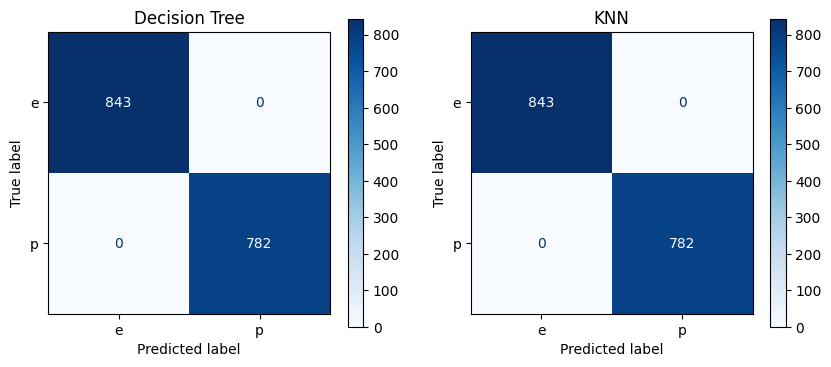

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(y_test, tree_pred, ax=axes[0], cmap="Blues")
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, ax=axes[1], cmap="Blues")
axes[1].set_title("KNN")

plt.show()

In [15]:
importance = pd.Series(tree.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(5)

,0
odor_n,0.623110
bruises_t,0.165583
odor_p,0.093090
odor_f,0.063447
spore-print-color_r,0.034084


## Conclusion

**Results**

| Model | Accuracy | Mistakes (out of 1,625 test mushrooms) |
|---|---|---|
| Decision Tree | 100% | 0 |
| KNN (k = 5) | 100% | 0 |

**Which model performed better?** Both models scored 100% and made zero
mistakes, so they tie on accuracy. I would choose the **Decision Tree**,
because it can explain its decisions. Its feature importances show that
**smell** is the most important clue: whether the mushroom has no odour,
a pungent odour or a foul odour makes up about 78% of its decisions,
followed by whether the mushroom bruises. KNN cannot explain itself in
this way, and it is also slower, since it compares every new mushroom
with all 6,499 training mushrooms.

**What I learned**
- Real data can hide missing values: stalk-root used "?" instead of
  blanks, so a normal missing-value check found nothing.
- Models need numbers, so I used one-hot encoding to turn letters into
  0/1 columns.
- Testing on unseen data (a train/test split) is what proves a model
  has really learned.
- For a safety problem like this, the confusion matrix matters more than
  accuracy alone: the most dangerous mistake is calling a poisonous
  mushroom edible, and both models made zero of these.